In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

data = pd.read_csv("data_grupp_13.csv")

X = data.drop(columns=["target"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

före pca, med alla utsprungliga dimensioner


In [2]:
dbscan = DBSCAN(eps=1.0, min_samples=5)

labels_original = dbscan.fit_predict(X_scaled)

med 90% varians

In [3]:
pca = PCA(n_components=0.90, svd_solver="full")

X_pca = pca.fit_transform(X_scaled)

print("Dimensioner före PCA:", X_scaled.shape[1])
print("Dimensioner efter PCA:", X_pca.shape[1])

print("Förklarad varians:",
      pca.explained_variance_ratio_.sum())

Dimensioner före PCA: 6
Dimensioner efter PCA: 4
Förklarad varians: 0.9391985996309891


efter pca

In [4]:
dbscan = DBSCAN(eps=1.0, min_samples=5)

labels_pca = dbscan.fit_predict(X_pca)

systematisk optimering före pca

In [9]:
resultat_fore = []

eps_values = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]

min_samples_values = [3, 5, 7, 10, 15]

for eps in eps_values:
    for min_pts in min_samples_values:

        dbscan = DBSCAN(eps=eps, min_samples=min_pts)

        labels = dbscan.fit_predict(X_scaled)

        antal_kluster = len(set(labels) - {-1})
        antal_brus = sum(labels == -1)
        andel_brus = antal_brus / len(labels) * 100

        mask = labels != -1

        if 2 <= antal_kluster < sum(mask):
            score = silhouette_score(
                X_scaled[mask], labels[mask]
            )
        else:
            score = None

        resultat_fore.append({
            "eps": eps,
            "min_samples": min_pts,
            "Kluster": antal_kluster,
            "Antal brus": antal_brus,
            "Brus (%)": andel_brus,
            "Silhouette": score
        })

resultat_fore_df = pd.DataFrame(resultat_fore)


tabell med bästa silhouette överst

In [10]:
display(resultat_fore_df.sort_values(
    "Silhouette", ascending=False
))

,eps,min_samples,Kluster,Antal brus,Brus (%),Silhouette
8,0.75,10,2,219,91.250000,0.777701
7,0.75,7,3,194,80.833333,0.733174
14,1.00,15,3,122,50.833333,0.640782
13,1.00,10,3,71,29.583333,0.595681
12,1.00,7,3,38,15.833333,0.565617
10,1.00,3,3,28,11.666667,0.555388
11,1.00,5,3,28,11.666667,0.555388
19,1.25,15,3,19,7.916667,0.543610
18,1.25,10,3,13,5.416667,0.534107
17,1.25,7,3,11,4.583333,0.530754


systematisk optimering efter pca

In [11]:
resultat_efter = []

for eps in eps_values:
    for min_pts in min_samples_values:

        dbscan = DBSCAN(eps=eps, min_samples=min_pts)

        labels = dbscan.fit_predict(X_pca)

        antal_kluster = len(set(labels) - {-1})
        antal_brus = sum(labels == -1)
        andel_brus = antal_brus / len(labels) * 100

        mask = labels != -1

        if 2 <= antal_kluster < sum(mask):
            score = silhouette_score(
                X_pca[mask], labels[mask]
            )
        else:
            score = None

        resultat_efter.append({
            "eps": eps,
            "min_samples": min_pts,
            "Kluster": antal_kluster,
            "Antal brus": antal_brus,
            "Brus (%)": andel_brus,
            "Silhouette": score
        })

resultat_efter_df = pd.DataFrame(resultat_efter)

display(resultat_efter_df.sort_values(
    "Silhouette", ascending=False
))

,eps,min_samples,Kluster,Antal brus,Brus (%),Silhouette
3,0.50,10,2,216,90.000000,0.840514
2,0.50,7,3,198,82.500000,0.825880
9,0.75,15,3,120,50.000000,0.708776
8,0.75,10,3,84,35.000000,0.667914
6,0.75,5,3,36,15.000000,0.618691
5,0.75,3,3,30,12.500000,0.612796
14,1.00,15,3,24,10.000000,0.607771
13,1.00,10,3,17,7.083333,0.598095
11,1.00,5,3,12,5.000000,0.589272
12,1.00,7,3,12,5.000000,0.589272


In [12]:
print("Bästa resultat före PCA:")

display(resultat_fore_df.sort_values(
    "Silhouette", ascending=False
).head(5))

print("Bästa resultat efter PCA:")

display(resultat_efter_df.sort_values(
    "Silhouette", ascending=False
).head(5))

Bästa resultat före PCA:


,eps,min_samples,Kluster,Antal brus,Brus (%),Silhouette
8,0.75,10,2,219,91.250000,0.777701
7,0.75,7,3,194,80.833333,0.733174
14,1.00,15,3,122,50.833333,0.640782
13,1.00,10,3,71,29.583333,0.595681
12,1.00,7,3,38,15.833333,0.565617


Bästa resultat efter PCA:


,eps,min_samples,Kluster,Antal brus,Brus (%),Silhouette
3,0.50,10,2,216,90.0,0.840514
2,0.50,7,3,198,82.5,0.825880
9,0.75,15,3,120,50.0,0.708776
8,0.75,10,3,84,35.0,0.667914
6,0.75,5,3,36,15.0,0.618691


Den översta raden har bäst Silhouette, men hela 219 av 240 kunder klassificeras som brus. Alltså beräknas silhoutte på bara 21 kunder.

Den andra eller tredje kombinationen kan därför vara mer användbar för kundsegmentering.

Test med gräns för maxbrus

In [25]:
max_brus = 20

print("Bästa resultat före PCA:")

display(
    resultat_fore_df[resultat_fore_df["Brus (%)"] <= max_brus]
    .sort_values("Silhouette", ascending=False)
    .head(5)
)

print("Bästa resultat efter PCA:")

display(
    resultat_efter_df[resultat_efter_df["Brus (%)"] <= max_brus]
    .sort_values("Silhouette", ascending=False)
    .head(5)
)

Bästa resultat före PCA:


,eps,min_samples,Kluster,Antal brus,Brus (%),Silhouette
12,1.00,7,3,38,15.833333,0.565617
10,1.00,3,3,28,11.666667,0.555388
11,1.00,5,3,28,11.666667,0.555388
19,1.25,15,3,19,7.916667,0.543610
18,1.25,10,3,13,5.416667,0.534107


Bästa resultat efter PCA:


,eps,min_samples,Kluster,Antal brus,Brus (%),Silhouette
6,0.75,5,3,36,15.000000,0.618691
5,0.75,3,3,30,12.500000,0.612796
14,1.00,15,3,24,10.000000,0.607771
13,1.00,10,3,17,7.083333,0.598095
11,1.00,5,3,12,5.000000,0.589272


optimala värden:


In [24]:
best_eps_fore = 1.0
best_min_fore = 7

best_eps_efter = 0.75
best_min_efter = 5

Mäta exekveringstid. 30 mätningar pga liten datamängd kan ge stor variation i tester

In [26]:
tider_fore = []

for i in range(30):

    dbscan = DBSCAN(
        eps=best_eps_fore,
        min_samples=best_min_fore
    )

    start = time.perf_counter()

    labels_best_fore = dbscan.fit_predict(X_scaled)

    slut = time.perf_counter()

    tider_fore.append(slut - start)

tid_fore = np.mean(tider_fore)

print("Genomsnittlig tid före PCA:", tid_fore)

Genomsnittlig tid före PCA: 0.002437850018031895


In [27]:
tider_efter = []

for i in range(30):

    dbscan = DBSCAN(
        eps=best_eps_efter,
        min_samples=best_min_efter
    )

    start = time.perf_counter()

    labels_best_efter = dbscan.fit_predict(X_pca)

    slut = time.perf_counter()

    tider_efter.append(slut - start)

tid_efter = np.mean(tider_efter)

print("Genomsnittlig tid efter PCA:", tid_efter)

Genomsnittlig tid efter PCA: 0.0013877266591104367


In [28]:
start = time.perf_counter()

pca_test = PCA(n_components=0.90, svd_solver="full")
pca_test.fit_transform(X_scaled)

slut = time.perf_counter()

tid_pca = slut - start

print("Tid för PCA:", tid_pca)
print("Total tid med PCA:", tid_pca + tid_efter)

Tid för PCA: 0.004137000069022179
Total tid med PCA: 0.005524726728132616


Resultat tabell och visuell:

In [29]:
sammanstallning = []

for namn, dataset, labels, eps, min_pts, tid in [
    ("Före PCA", X_scaled, labels_best_fore,
     best_eps_fore, best_min_fore, tid_fore),

    ("Efter PCA", X_pca, labels_best_efter,
     best_eps_efter, best_min_efter, tid_efter)
]:

    mask = labels != -1
    antal_kluster = len(set(labels) - {-1})

    if 2 <= antal_kluster < sum(mask):
        score = silhouette_score(
            dataset[mask], labels[mask]
        )
    else:
        score = None

    sammanstallning.append({
        "Metod": namn,
        "Dimensioner": dataset.shape[1],
        "eps": eps,
        "min_samples": min_pts,
        "Kluster": antal_kluster,
        "Brus (%)": sum(labels == -1) / len(labels) * 100,
        "Silhouette": score,
        "Tid (sek)": tid
    })

sammanstallning_df = pd.DataFrame(sammanstallning)

display(sammanstallning_df.round(6))

,Metod,Dimensioner,eps,min_samples,Kluster,Brus (%),Silhouette,Tid (sek)
0,Före PCA,6,1.00,7,3,15.833333,0.565617,0.002438
1,Efter PCA,4,0.75,5,3,15.000000,0.618691,0.001388


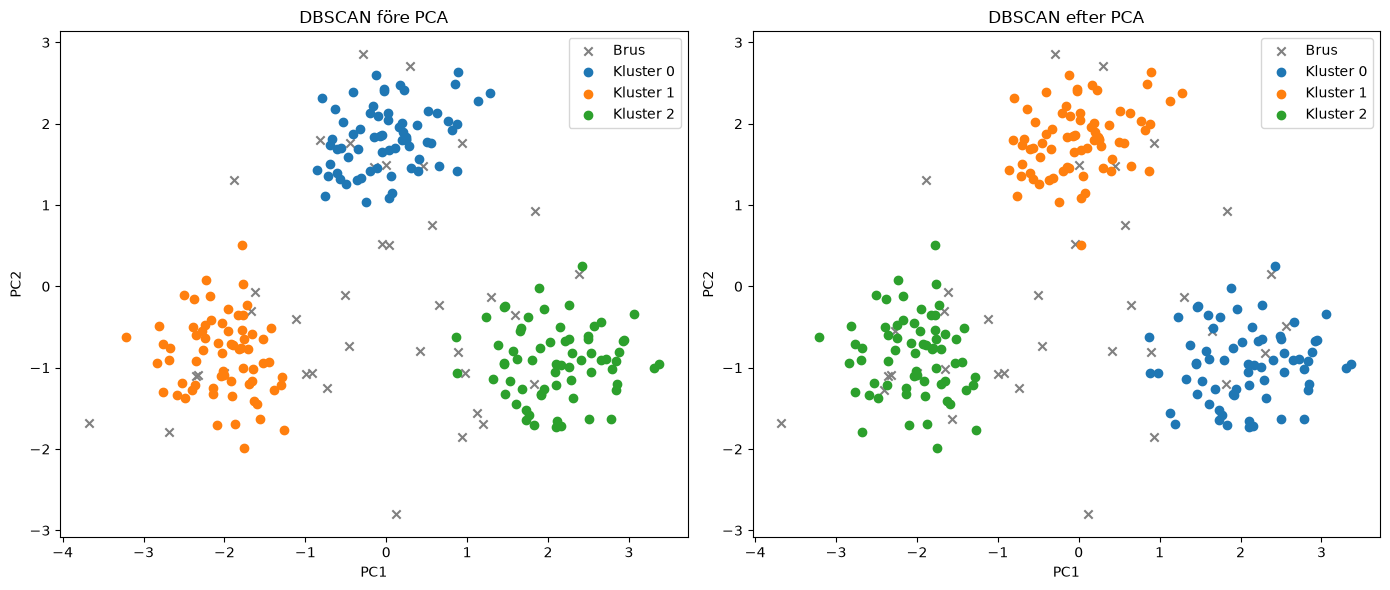

In [30]:
pca_2d = PCA(n_components=2, random_state=42)

X_pca_2d = pca_2d.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, labels, titel in [
    (axes[0], labels_best_fore, "DBSCAN före PCA"),
    (axes[1], labels_best_efter, "DBSCAN efter PCA")
]:

    for label in sorted(set(labels)):

        mask = labels == label

        if label == -1:
            ax.scatter(
                X_pca_2d[mask, 0],
                X_pca_2d[mask, 1],
                color="gray",
                marker="x",
                label="Brus"
            )
        else:
            ax.scatter(
                X_pca_2d[mask, 0],
                X_pca_2d[mask, 1],
                label=f"Kluster {label}"
            )

    ax.set_title(titel)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()

plt.tight_layout()
plt.show()

Domänanalys:

In [31]:
kundanalys = X.copy()

kundanalys["Kluster"] = labels_best_efter

display(kundanalys.groupby("Kluster").mean().round(2))

,besok_per_manad,snittorder_kr,tid_pa_sajt_sek,returgrad,kundtjanst_arenden,rabattkod_andel
Kluster,,,,,,
-1,14.75,1266.47,295.17,0.28,3.65,0.38
0,13.54,2528.96,535.03,0.05,0.61,0.19
1,16.73,503.57,191.25,0.11,0.98,0.79
2,3.37,838.95,88.48,0.46,4.12,0.35


In [32]:
display(pd.crosstab(
    labels_best_efter,
    data["target"],
    rownames=["Kluster"]
))

target,Fyndjagare,Lojal_stamkund,Risk_for_churn
Kluster,,,
-1,8,12,16
0,0,68,0
1,72,0,0
2,0,0,64


Här syns tydligt att den hittar alla våra kundgrupper, i tre kluster, med lite brus. I vårt dataset, utan att veta target.